<img width="1600" height="436" alt="Logo + Title+ Slogan Modified (Updated)" src="https://github.com/user-attachments/assets/e8bda4e2-6039-45f9-ab40-070ea569c98b" />

![Robotics Dojo Banner](https://github.com/user-attachments/assets/e8bda4e2-6039-45f9-ab40-070ea569c98b)

# Waste Management AI Training Notebook

**Purpose:** This notebook is used to train an Object-Detection Model (YOLO26) for use on the Raspberry Pi. 

### Prototype classes
- `organic` → e.g.  **watermelon**
- `plastic` e.g.  **bottle**
- `other` →  e.g. **clothing, metals, etc**

### Pipeline Overview
1. Dataset Curation: Data + Labels
2. train/val/test split
3. Pretrained YOLO → training
4. Validation + error analysis
5. Model Conversions & exports
6. Deployable for the Raspberry Pi


## 0. Imports and project configuration

This cell creates the folders used by the notebook and defines the three classes.

Class IDs must remain consistent:
- `0 = organic`
- `1 = plastic`
- `2 = other`


In [1]:
from pathlib import Path
import random
import shutil
import yaml
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

PROJECT = Path.cwd() / "rdj2026-v2i-yolov8"
RAW_DIR = PROJECT / "raw"
DATASET_DIR = PROJECT
EXPORT_DIR = PROJECT / "exports"

for p in [RAW_DIR, DATASET_DIR, EXPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

CLASSES = ["metal", "organic", "plastic"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}

SEED = 82
random.seed(SEED)
np.random.seed(SEED)

print("Project:", PROJECT)
print("Classes:", CLASS_TO_ID)


Project: /workspace/rdj2026-v2i-yolov8
Classes: {'metal': 0, 'organic': 1, 'plastic': 2}


## 1. Dataset Curation

We use a dataset that was prepared by the Robotics Dojo Interns 2026


In [5]:
yaml_path = DATASET_DIR / "data.yaml"

print(yaml_path.read_text())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['metal', 'organic', 'plastic']

roboflow:
  workspace: nikita-kamau
  project: rdj2026
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/nikita-kamau/rdj2026/dataset/2


### Inspect the data before training

Quick sanity check to ensure the dataset is okay to proceed


In [ ]:
# Add Code here

## 2. train/validation/test folders

Ultralytics YOLO expects images and matching label files.

Each label line is:

`class_id x_center y_center width height`

with all coordinates normalized from 0 to 1.


In [7]:
# Add Code here

### Split the dataset

We create:
- 70% training
- 20% validation
- 10% test

The test set is kept separate and should only be used for the final evaluation.


In [ ]:
# Add code here

# Since the provided dataset already is split, this step is unnecessary

### Check class balance

A model can look good overall while performing badly on one class.

We count labels for each class before training.


In [6]:
# Check Class balance

from collections import Counter

counts = Counter()

for split in ["train", "val", "test"]:
    for label_file in (DATASET_DIR / split / "labels").glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                counts[CLASSES[class_id]] += 1

print("Object counts:")
for name in CLASSES:
    print(f"{name:10s}: {counts[name]}")

Object counts:
metal     : 535
organic   : 919
plastic   : 605


### Visual sanity check

Before training, display a few training images with their bounding boxes.

If the boxes or class IDs are wrong, **stop here and fix the dataset**.


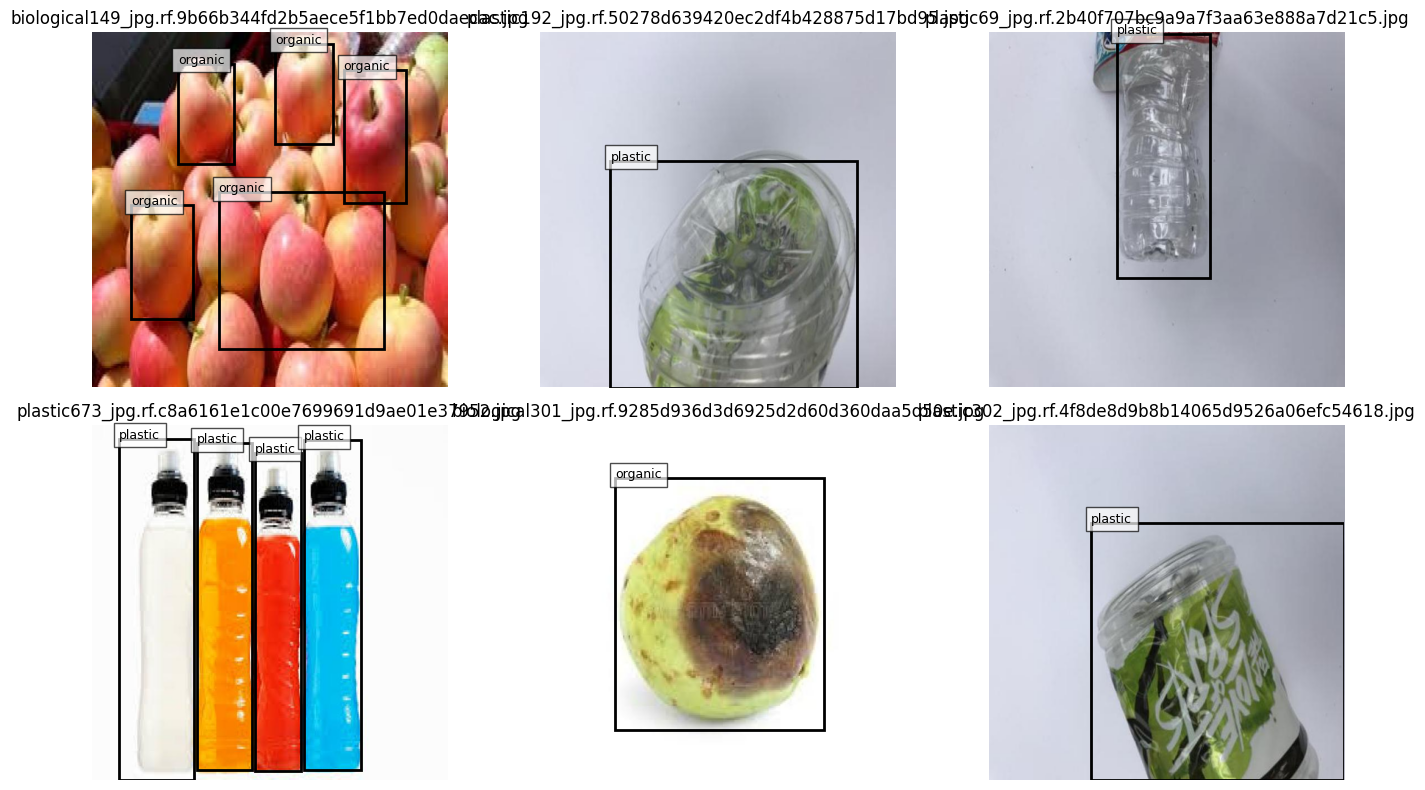

In [10]:
def show_samples(split="train", n=6):
    image_dir = DATASET_DIR / split / "images"
    images = list(image_dir.glob("*"))
    random.Random(SEED).shuffle(images)
    images = images[:n]

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes = axes.flatten()

    for ax, img_path in zip(axes, images):
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(img_path.name)
        ax.axis("off")

        label_path = DATASET_DIR / split / "labels" / f"{img_path.stem}.txt"
        if label_path.exists():
            W, H = img.size
            for line in label_path.read_text().splitlines():
                cls, xc, yc, w, h = map(float, line.split()[:5])
                x1 = (xc - w/2) * W
                y1 = (yc - h/2) * H
                bw = w * W
                bh = h * H
                rect = plt.Rectangle((x1, y1), bw, bh, fill=False, linewidth=2)
                ax.add_patch(rect)
                ax.text(x1, y1, CLASSES[int(cls)], fontsize=9,
                        bbox=dict(facecolor="white", alpha=0.7))

    plt.tight_layout()
    plt.show()

show_samples()


## 3. Train a small pretrained YOLO model

We start with a **small pretrained detection model** so the model can train quickly.

Training Settings:
- `epochs=30`
- batch



In [ ]:
from ultralytics import YOLO

MODEL_NAME = "yolo26n.pt"

model = YOLO(MODEL_NAME)

results = model.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=-1,
    patience=10,
    project=str(PROJECT / "training_runs"),
    name="production",
    exist_ok=True,
)

print("Training finished.")


## 4. Validate the trained model (val set)

Validation answers:

> "How well does the model detect the classes on images it did not train on?"

Pay attention to:
- mAP50
- mAP50-95
- precision
- recall
- per-class performance


In [ ]:
best_model_path = PROJECT / "training_runs" / "production" / "weights" / "best.pt"
best_model = YOLO(str(best_model_path))

metrics = best_model.val(
    data=str(yaml_path),
    split="val",
    imgsz=640,
)

print("mAP50-95:", metrics.box.map)
print("mAP50:", metrics.box.map50)
print("Per-class mAP50-95:", metrics.box.maps)


### Test on completely unseen images (test set)

The test set should be treated as the final exam.


In [ ]:
test_metrics = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
)

print("TEST mAP50-95:", test_metrics.box.map)
print("TEST mAP50:", test_metrics.box.map50)
print("TEST per-class mAP50-95:", test_metrics.box.maps)


### Run inference on test images

> **Does the model put the correct box around the correct waste object?**


In [ ]:
test_images = list((DATASET_DIR / "images" / "test").glob("*"))

predictions = best_model.predict(
    source=[str(p) for p in test_images[:12]],
    imgsz=640,
    conf=0.25,
    save=True,
    project=str(PROJECT / "predictions"),
    name="test_predictions",
    exist_ok=True,
)

print("Prediction images saved to:", PROJECT / "predictions" / "test_predictions")


## 5. Model Conversions

The important artifact is:

`best.pt`

Also save:
- `data.yaml`
- the dataset
- training results
- this notebook
- a requirements file
- a README describing the experiment

This makes the experiment reproducible on another computer.


In [ ]:
requirements = 'ultralytics\nfiftyone\npyyaml\nnumpy\npillow\nmatplotlib\n'
(EXPORT_DIR / "requirements.txt").write_text(requirements)

# Copy the best model into a simple export location.
hpc_model = EXPORT_DIR / "best.pt"
shutil.copy2(best_model_path, hpc_model)

# Copy data.yaml
shutil.copy2(yaml_path, EXPORT_DIR / "data.yaml")

print("HPC model:", hpc_model)
print("Requirements:", EXPORT_DIR / "requirements.txt")


### Convert model to NCNN Format

Ultralytics officially recommends NCNN as the highest-performing option for ARM-based embedded CPUs

https://docs.ultralytics.com/guides/raspberry-pi


In [ ]:
# Load your trained YOLO26n PyTorch model
model = YOLO("yolo26n.pt")

# Export to highly optimized NCNN format
model.export(format="ncnn")

### Convert model to ONNX Format

In [ ]:
# Export to ONNX format
model.export(format="onnx")

### Convert model to HEIF Format

This is for use specifically with the AI HAT+ (Hailo-8L) accelerator

- HEIF: Hailo Executable Format

In [ ]:
# Export to HEIF format
# (Note: This requires the Hailo Dataflow Compiler toolchain installed)
model.export(format="hailo")

## 6. Raspberry Pi Deployment

Robotics Dojo provides a ROS2 Package that utilizes the trained model, with support for both CPU-only and Accelerator-enabled inference:

- Use NCNN for CPU-Only inference
- Use HEIF for Accelerator-enabled inference

More info about the Robotics Dojo ROS2 Package

In [ ]:
import zipfile

zip_path = EXPORT_DIR / "waste_ai_prototype_for_hpc.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    # Dataset
    for p in DATASET_DIR.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(PROJECT))

    # Best model
    z.write(hpc_model, hpc_model.relative_to(PROJECT))

    # Requirements
    req = EXPORT_DIR / "requirements.txt"
    z.write(req, req.relative_to(PROJECT))

print("Package created:", zip_path)


# GLHF ;)